This notebook reproduces panels (d)-(e) of Fig. 2 (see `Fig02abc-LZ.ipynb` for the definition of the pulses and the fidelity).

In the presence of dephasing, the system is modeled via a Lindblad master equation given by
$$
\dot{\rho}(t) = -i\left[H(t), \rho(t)\right]+\mathcal{D}[\rho(t)], \qquad \mathcal{D}[\rho]=\gamma\left(\sigma_z\rho\sigma_z-\rho\right)=\frac{1}{T_2}\left[\operatorname{diag}(\rho) - \rho\right],
$$
i.e., with the jump operator $\sqrt{\gamma}\,\sigma_z$ and $\gamma = 1 /(2 T_2)$. Here, $\gamma=0.005\,x$, i.e., $T_2=100/x$. The fidelity is now defined as $\mathcal{F} = \bra{\psi_0(t_\mathrm{f})}\rho(t_\mathrm{f})\ket{\psi_0(t_\mathrm{f})}$. The dashed black line in panel (e) is the bound for an ideal $\pi$-pulse, $1-\mathcal{F}_{\pi\text{-pulse}}\geq[1-\exp(-t_\mathrm{f}/2T_2)]/2$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from HQUAD_lib.QUAD_utils import solve_LZ
from HQUAD_lib.parallel_utils import parameter_run
from HQUAD_lib.plotting_utils import plot_gradient_lines
from HQUAD_lib.physics_utils import fidelity_LZ

In [ ]:
x = 1

n_alphas = 21  # Increase for higher resolution
alphas = np.linspace(-4, 4, n_alphas)
alphas[0] = -np.inf
alphas[-1] = np.inf

betas = alphas

gamma = 0.005

tfs = np.linspace(0.1, 10, 100)


def compute_fidelity_total(alpha, beta, gamma):
    pulse = solve_LZ(alpha, beta, x=x)

    fidelitites = parameter_run(
        fidelity_LZ,
        "tf",
        tfs,
        pulse=pulse,
        x=x,
        z0=-10,
        gamma=gamma,
        pbar_kwargs={"leave": False},
    )
    return fidelitites

In [ ]:
fidelities_pure = np.zeros((n_alphas, len(tfs)))
pbar = tqdm(total=n_alphas, desc="Computing fidelitites")
for i in range(n_alphas):
    fidelities_pure[i] = compute_fidelity_total(alphas[i], betas[i], gamma=0)
    pbar.update()
pbar.close()

Computing fidelitites:   0%|          | 0/21 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

...

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

In [ ]:
fidelities_dephasing = np.zeros((n_alphas, len(tfs)))
pbar = tqdm(total=n_alphas, desc="Computing fidelitites")
for i in range(n_alphas):
    fidelities_dephasing[i] = compute_fidelity_total(alphas[i], betas[i], gamma=gamma)
    pbar.update()
pbar.close()

Computing fidelitites:   0%|          | 0/21 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

...

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/100 [00:00<?, ?it/s]

c:\Users\vawi76si\OneDrive-UniA\Projects\Alpha-beta-hypergeo\HQUAD_lib\plotting_utils.py:75: UserWarning: Overwriting the cmap 'shiftedcmap' that was already in the registry.
  colormaps.register(cmap=newcmap, force=True)


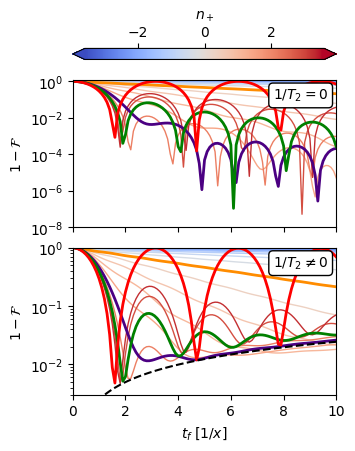

In [ ]:
fig, axs = plt.subplots(
    3, 1, figsize=(3.4, 4.5), gridspec_kw=dict(height_ratios=[0.075, 1, 1])
)

ax, sm = plot_gradient_lines(
    tfs,
    1 - fidelities_pure,
    alphas,
    betas,
    y_label=r"$1 - \mathcal{F}$",
    ax=axs[1],
    legend_bool=False,
    cbar_bool=False,
)

axs[1].text(
    0.97,
    0.95,
    r"$1 / T_2 = 0$",
    ha="right",
    transform=axs[1].transAxes,
    va="top",
    bbox=dict(boxstyle="round", ec="k", fc="w", alpha=1),
)

axs[1].set_ylim(1e-8, 1.2)
axs[1].set_xticklabels([])

ax, sm = plot_gradient_lines(
    tfs,
    1 - fidelities_dephasing,
    alphas,
    betas,
    x_label=r"$t_f \; [1 / x]$",
    y_label=r"$1 - \mathcal{F}$",
    ax=axs[2],
    legend_bool=False,
    cbar_bool=False,
)

axs[2].text(
    0.97,
    0.95,
    r"$1 / T_2 \neq 0$",
    ha="right",
    transform=axs[2].transAxes,
    va="top",
    bbox=dict(boxstyle="round", ec="k", fc="w", alpha=1),
)

axs[2].set_ylim(3e-3, 1)

axs[2].plot(tfs, 1 / 2 * (1 - np.exp(-tfs * gamma)), ls="--", c="k")

plt.colorbar(
    sm,
    cax=axs[0],
    label=r"$n_+ $",
    orientation="horizontal",
    location="top",
    extend="both",
)

for ax in axs[1:]:
    ax.set_xlim(0, 10)
    ax.set_yscale("log")